In [2]:
import sys

if sys.version_info[0] + 0.1 * sys.version_info[1] < 3.6:
    raise Exception("Must be using Python 3.6+ version")

In [3]:
%matplotlib inline
sys.path.append("..")
from wavelet_transform.wpt import transform as wpt
from wavelet_transform.test import synthetic_data as sd
from wavelet_transform.wpt import inverse_transform as inv
from wavelet_transform.postprocess import plotting as plot
import wavelet_transform.utils.statistical_features as stats
from wavelet_transform.utils.bubbledynamics import BubbleDynamics as BD

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

### Set pararmeters for bubble dynamics model

In [4]:
pac = -5E5                                  # the amplitude of the sine wave in Pa
frequency = 5E5                  # insonation frequency (Hz)
no_cycle = 20                               # no. of cycles of the sine wave
sampling_rate = frequency * 20      # sampling rate to generate the time vector
tstep = 1. / sampling_rate
tmax = no_cycle / frequency
time = np.arange(0., tmax, tstep) # time vector for computing the sine wave, in seconds
t_plot = time

R_init = 10E-6                  # initial bubble radius in meters
Rdot_init = 0                   # initial bubble's wall velocity in m/s

r_measure = 50*R_init           # distance from the centre of bubble which radiated pressure (acoustic emission from bubble) is calculated over time 

std_noise = 0.01

wavelet = "db20"
levels = 4
mode = "symmetric"

fft_lim = 10 * frequency  # increase value to view more of the fft plots

In [5]:
    
def generate_data(R_init, Rdot_init, frequency, pac, time, tstep, r_measure):
    # generate sound wave

    BD_obj = BD(R_init, Rdot_init, frequency, pac, time, tstep)
    BD_obj.solver()
    BD_obj.calculate_p_radiated(r_measure=r_measure)

    data = BD_obj.p_radiated
    time = BD_obj.time

    return data


In [6]:
def generate_training_data(data, levels, wavelet, mode, sampling_rate):
    # DWPT
    tr_ob = wpt.dwpt(data, levels, wavelet, mode)
    tr_ob.calc_frequencies(sampling_rate)

    # calculate energy, kurtosis, and crest factor of reconstructed signals
    wpt_df = pd.DataFrame(
        columns=[
            "node",
            "inverse",
            "fft",
            "energy",
            "kurtosis",
            "crest",
            "entropy",
            "skewness",
        ]
    )

    total_energy = stats.calc_energy(data)

    # reconstruct each node separately
    for node in tr_ob.get_level(level=levels, order="freq"):
        node_data = node.data  # coefficients from transform

        # calculate inverse transform
        inverse = inv.inv_dwpt(tr_ob, level=levels, nodes=node)
        inverse_signal_length = len(inverse)

        # calculate fft of inverse
        fft = np.fft.fft(inverse)[0 : int(inverse_signal_length / 2)] / (
            inverse_signal_length * 0.5
        )

        # calculate statistical measures
        entropy_node = stats.calc_entropy(node.energy, total_energy)
        kurtosis = stats.calc_kurtosis(node_data)
        skewness = stats.calc_skewness(node_data)
        crest = stats.calc_crest_factor(node_data)

        counter = node.node_number
        wpt_df.loc[counter, "node"] = node
        wpt_df.loc[counter, "inverse"] = inverse
        wpt_df.loc[counter, "fft"] = fft
        wpt_df.loc[counter, "energy"] = node.energy
        wpt_df.loc[counter, "kurtosis"] = kurtosis
        wpt_df.loc[counter, "crest"] = crest
        wpt_df.loc[counter, "entropy"] = entropy_node
        wpt_df.loc[counter, "skewness"] = skewness

    return wpt_df

### Training data

Run bubble dynamics over a range of frequencies and intensities to generate a larger array of training data.

In [7]:
wpt_df = pd.DataFrame(
        columns=[
            "node",
            "inverse",
            "fft",
            "energy",
            "kurtosis",
            "crest",
            "entropy",
            "skewness",
        ]
    )

for frequency in [i * 1E5 for i in range(1, 20)]:
    for pac in [-i * 1E5 for i in range(1, 10)]:
        data = generate_data(R_init, Rdot_init, frequency, pac, time, tstep, r_measure)
        if max(data) > 100 or np.isnan(data).any():
            continue
        data -= np.mean(data)
        # plt.plot(data)
        # plt.show()
        training_data = generate_training_data(data, levels, wavelet, mode, sampling_rate)
        wpt_df = pd.concat([wpt_df, training_data], ignore_index=True)


### Training

Train fuzzy c-means on the generated data

In [8]:
from sklearn.preprocessing import StandardScaler
import skfuzzy as fuzz

# get data
classifying_metrics = ["entropy", "kurtosis", "skewness"]
data_train = wpt_df[classifying_metrics]

# standardise data
scaler = StandardScaler()
data_train_normalised = scaler.fit_transform(data_train)

# parameters for Fuzzy C-means
no_clusters = 5
m = 2.0
error = 1e-6

# Fuzzy C-Means clustering
cntr, u, u0, d, jm, p, fpc = fuzz.cluster.cmeans(
    data_train_normalised.T,
    c=no_clusters,
    m=m,
    error=error,
    maxiter=100,
)
print("number of iterations:", p)
# cluster centres
print("centres", cntr)
centers = scaler.inverse_transform(cntr)

# membership matrix
membership_matrix = u.T

# hard cluster assignments
labels = np.argmax(membership_matrix, axis=1)
for i in range(no_clusters):
    print(f"label {i} count:", list(labels).count(i))

membership_results = pd.DataFrame()
for i, membership in enumerate(membership_matrix):
    membership_results.loc[i, "hard assignment"] = labels[i]
    for j in range(no_clusters):
        membership_results.loc[i, f"membership {j}"] = membership[j]

membership_results.head()

number of iterations: 99
centres [[ 0.22635186 -0.44492093 -0.0409099 ]
 [ 0.24671613  1.06857234 -1.62845568]
 [ 0.26364834  3.17212591  2.97680896]
 [-4.33583456 -0.72452025  0.04116271]
 [ 0.22509144  0.07890765  0.6319494 ]]
label 0 count: 1606
label 1 count: 338
label 2 count: 75
label 3 count: 133
label 4 count: 568


,hard assignment,membership 0,membership 1,membership 2,membership 3,membership 4
0,0.0,0.582149,0.068518,0.010888,0.009466,0.328979
1,0.0,0.556110,0.097868,0.022095,0.041121,0.282807
2,0.0,0.934405,0.006877,0.001562,0.001711,0.055445
3,4.0,0.443368,0.022275,0.008319,0.007419,0.518619
4,0.0,0.876520,0.011703,0.002494,0.002384,0.106898


In [9]:
def map_labels_entropy(centers, sort_by=1):
    """
    assign labels to clusters. Assign the highest cluster number to the centre with
    lowest entropy. Then assign the rest in order of sort_by. The group numbers are reassigned
    to 1-indexed groups.

    Paramaters
    -----------
    centers: array
        array where each row is a centre of a cluster
    labels: list
        list of group assignments to reassign
    sort_by: int
        always sort out the highest energy because the harmonic can be separated
        from the rest by its much greater energy. Otherwise, sort by attribute
        number = sort_by of the centres. e.g. sort_by == 1 will sort the rest
        by kurtosis, sort_by == 2 will sort by crest factor etc.
    """
    # sort labels by entropy, lowest entropy is highest group number
    sort_by_entropy = np.argsort(centers[:, 0])[::-1]  # assumes entropy is in 1st position

    # sort rest of the labels by kurtosis
    sort_rest = np.argsort(centers[:, sort_by])

    sort_rest = np.delete(
        sort_rest,  # delete lowest entropy group form kurtosis
        np.where(sort_rest == sort_by_entropy[-1])[0][0],
        axis=0,
    )
    sort_rest = np.append(sort_rest, None)

    # create mapping from old cluster labels to new cluster labels
    mapping = {}
    for new_label, index in enumerate(zip(sort_by_entropy, sort_rest)):
        if new_label == len(sort_by_entropy) - 1:  # highest group no has highest energy
            mapping[index[0]] = new_label + 1
        else:
            mapping[index[1]] = (
                new_label + 1
            )  # other group numbers are arranged by kurtosis

    return mapping

### Reassigning labels

Post-hoc assignment of labels

In [10]:
mapping = map_labels_entropy(centers)
print(mapping)

{0: 1, 4: 2, 1: 3, 2: 4, 3: 5}


Hard assignments

In [31]:
def reassign_labels(mapping, labels):
    # reassigning labels
    reassigned_labels = [mapping[label] for label in labels]
    return reassigned_labels

reassigned_labels = reassign_labels(mapping, labels)
print(reassigned_labels)
for i in range(1, no_clusters + 1):
    print(f"label {i} count:", list(reassigned_labels).count(i))

[1, 1, 1, 2, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 3, 1, 1, 1, 2, 1, 1, 2, 1, 1, 1, 1, 3, 1, 1, 1, 3, 2, 2, 3, 3, 3, 2, 3, 1, 1, 4, 2, 2, 3, 2, 2, 3, 2, 4, 2, 2, 4, 2, 4, 4, 4, 3, 2, 3, 4, 3, 4, 3, 1, 1, 3, 3, 3, 2, 2, 4, 1, 3, 3, 3, 3, 2, 3, 1, 1, 3, 2, 2, 3, 2, 2, 2, 2, 4, 1, 3, 2, 2, 4, 5, 1, 2, 1, 3, 4, 1, 2, 3, 1, 4, 2, 3, 3, 1, 3, 1, 1, 4, 4, 1, 3, 3, 3, 1, 2, 4, 4, 1, 4, 3, 4, 1, 1, 1, 2, 1, 2, 1, 1, 4, 1, 2, 1, 2, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 1, 1, 1, 1, 2, 1, 1, 2, 1, 1, 2, 2, 1, 2, 1, 2, 3, 3, 4, 2, 2, 2, 2, 3, 1, 1, 2, 1, 1, 3, 1, 1, 1, 1, 4, 3, 1, 3, 2, 2, 1, 1, 2, 2, 1, 1, 2, 3, 1, 1, 2, 2, 1, 2, 1, 2, 5, 1, 1, 1, 3, 2, 1, 1, 2, 3, 4, 2, 3, 2, 1, 2, 2, 3, 3, 2, 1, 4, 3, 3, 3, 3, 4, 3, 3, 4, 3, 3, 1, 1, 2, 3, 1, 2, 3, 3, 3, 2, 3, 3, 2, 4, 2, 4, 5, 1, 2, 3, 1, 2, 1, 1, 2, 1, 1, 1, 1, 1, 2, 3, 1, 2, 1, 1, 1, 1, 1, 1, 1, 1, 2, 2, 1, 2, 1, 2, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 3, 1, 1, 1, 4, 1, 1, 2, 2, 1, 4, 1, 2, 2, 3, 4, 3, 4, 3, 3, 4, 2, 3, 

Soft assignments

In [32]:
def generate_soft_assignments(mapping, membership_matrix):
    soft_assignments = [
        sum([mapping[i] * weight for i, weight in enumerate(membership)])
        for membership in membership_matrix
    ]
    return soft_assignments

soft_assignments = generate_soft_assignments(mapping, membership_matrix)
print(soft_assignments)

[1.5365440611801127, 1.7093084767301516, 1.0807281153220345, 1.6178009944393157, 1.1473235151836474, 1.0078830180683638, 1.0594169476208317, 1.247909020256646, 1.1009973795597123, 1.0538447128198238, 1.2182202466326189, 1.2530113988569562, 1.1985349425105978, 1.0468873644393657, 1.198364681988108, 1.1853729200878915, 2.8847141945539163, 1.416468116244534, 1.38436624092328, 1.1200334891368517, 1.8594365958094319, 1.0906127306378894, 1.123809595214569, 2.69609128030596, 1.2117790060717046, 1.0067071253267394, 1.1283380050816574, 1.016280304114346, 2.1869608639643054, 1.4424236686359988, 1.1846040982262114, 1.7573433079207919, 2.4110943365392883, 1.9888826162608193, 1.6020419691132353, 2.62635938813783, 2.901450801534759, 2.86659348050473, 1.9931399938321417, 2.5027135507363174, 1.3971933245124148, 1.574258573654957, 3.944208814175782, 1.9835468662422628, 2.231360295681471, 2.5415342960930767, 1.9577248889994823, 2.3256295076592424, 2.164193543668825, 2.282114176229806, 3.6900610098789164

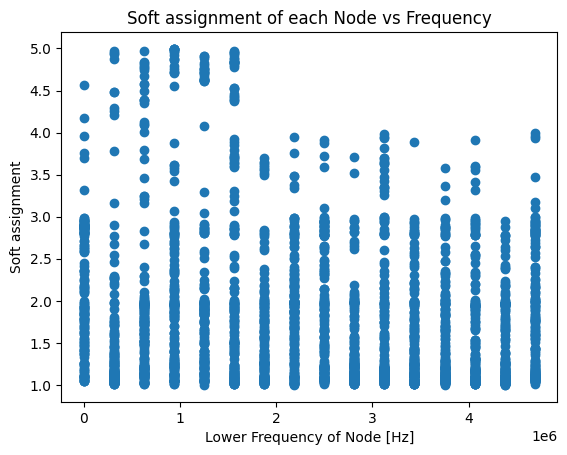

In [13]:
# plot weighted reassigned labels
plt.scatter([node.frequency_range[0] for node in wpt_df["node"]], soft_assignments)
plt.title("Soft assignment of each Node vs Frequency")
plt.xlabel("Lower Frequency of Node [Hz]")
plt.ylabel("Soft assignment")
plt.show()

Plotting clustering results

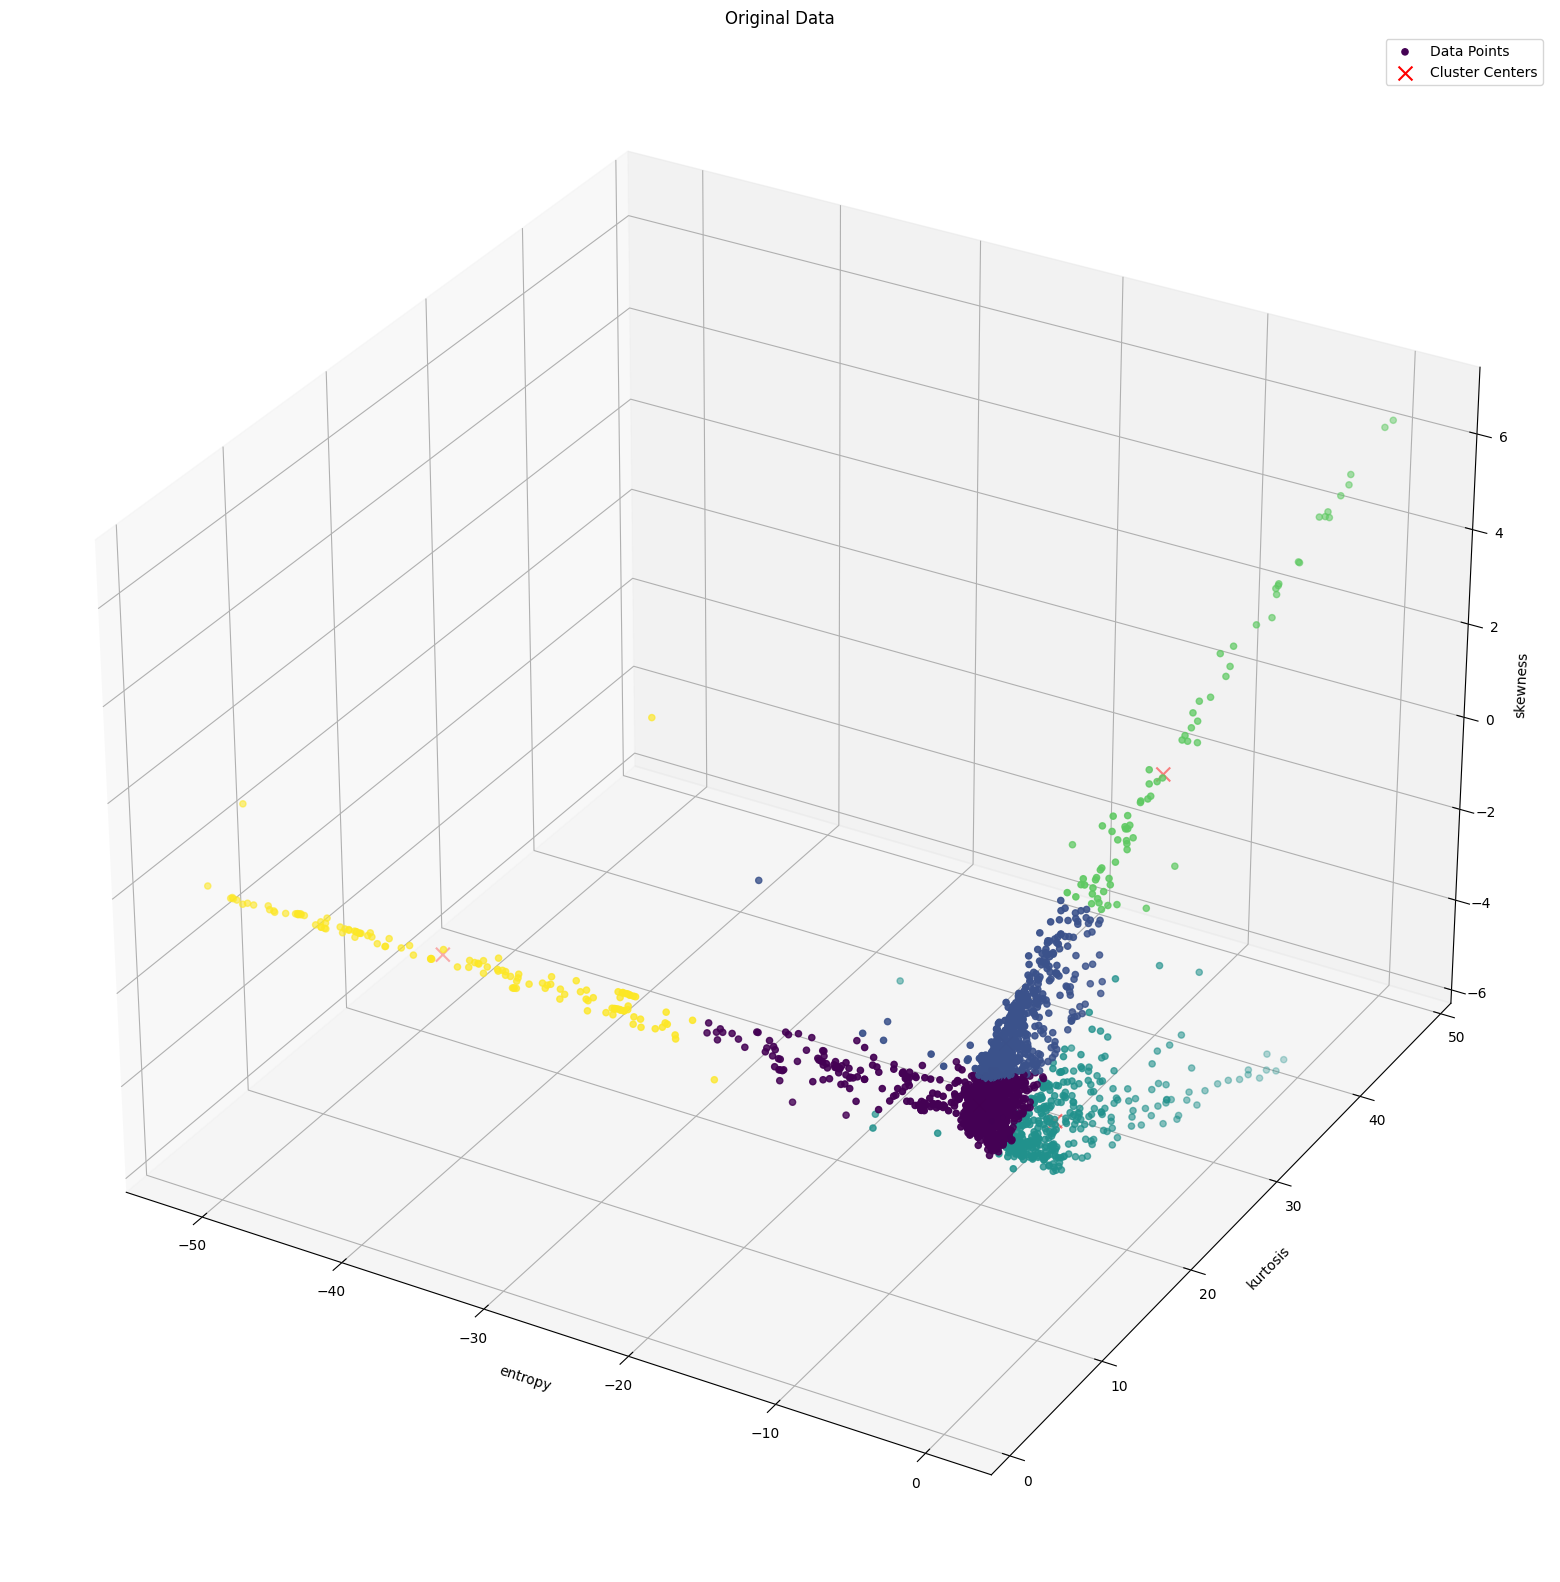

In [14]:
import matplotlib.pyplot as plt

fig = plt.figure(figsize=(20, 20))
ax = fig.add_subplot(111, projection="3d")

title = "Original Data"

data_scatter = data_train.values.tolist()
centers_scatter = centers
labels_scatter = reassigned_labels
color_map_labels = reassigned_labels

# Plot data points
data_plot = ax.scatter(
    [point[0] for point in data_scatter],
    [point[1] for point in data_scatter],
    [point[2] for point in data_scatter],
    c=color_map_labels
)

# Plot cluster centers after data points
center_plot = ax.scatter(
    centers_scatter[:, 0],
    centers_scatter[:, 1],
    centers_scatter[:, 2],
    c="red",
    marker="x",
    s=100,
)

ax.set_xlabel(data_train.columns[0])
ax.set_ylabel(data_train.columns[1])
ax.set_zlabel(data_train.columns[2])
ax.set_title(title)

# Make sure the cluster centers plot appears in front
ax.legend([data_plot, center_plot], ["Data Points", "Cluster Centers"])

plt.show()


### Classifying new data points

In [85]:
frequency = 10E5
pac = -10E5

data = generate_data(R_init, Rdot_init, frequency, pac, time, tstep, r_measure)
data -= np.mean(data)
new_wpt_df = generate_training_data(data, levels, wavelet, mode, sampling_rate)

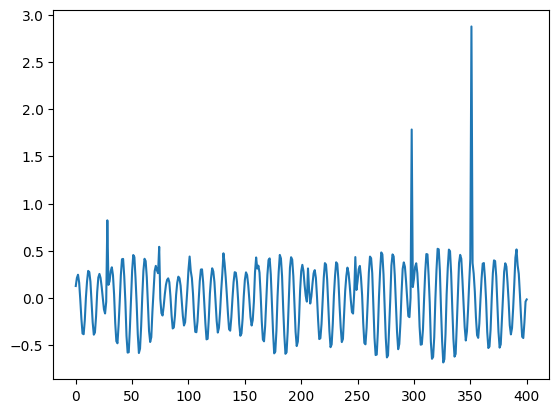

In [86]:
plt.plot(data)
plt.show()

In [87]:
# Assuming you have the new entry data in a variable called "new_entry"
new_entry = new_wpt_df[classifying_metrics]

# Standardize the new entry using the same scaler
new_entry_normalized = scaler.transform(new_entry)

# Predict membership using the cluster centers and membership matrix
new_u, *_ = fuzz.cluster.cmeans_predict(
    new_entry_normalized.T,
    cntr,
    m=m,
    error=error,
    maxiter=100,
)

new_membership_matrix = new_u.T
# Convert membership to hard cluster assignment
new_labels = np.argmax(new_u, axis=0)

# Display the predicted results
print("Predicted hard cluster assignment:", new_labels)

membership_results = pd.DataFrame()
for i, membership in enumerate(new_membership_matrix):
    membership_results.loc[i, "hard assignment"] = new_labels[i]
    for j in range(no_clusters):
        membership_results.loc[i, f"membership {j}"] = membership[j]

membership_results.head()

Predicted hard cluster assignment: [0 0 0 3 0 0 0 0 1 4 4 1 0 0 0 4]


,hard assignment,membership 0,membership 1,membership 2,membership 3,membership 4
0,0.0,0.936853,0.012175,0.002211,0.002603,0.046159
1,0.0,0.774407,0.069538,0.008782,0.009879,0.137394
2,0.0,0.904155,0.010894,0.002862,0.003174,0.078915
3,3.0,0.085420,0.057849,0.027629,0.750627,0.078474
4,0.0,0.725599,0.022041,0.007088,0.007153,0.238119


In [88]:
# reassigning labels
reassigned_labels = reassign_labels(mapping, new_labels)
print(reassigned_labels)
for i in range(1, no_clusters + 1):
    print(f"label {i} count:", list(reassigned_labels).count(i))

[1, 1, 1, 5, 1, 1, 1, 1, 3, 2, 2, 3, 1, 1, 1, 2]
label 1 count: 10
label 2 count: 3
label 3 count: 2
label 4 count: 0
label 5 count: 1


In [89]:
new_soft_assignments = generate_soft_assignments(mapping, new_membership_matrix)
print(soft_assignments)

[1.9076240432881622, 1.0730769134552076, 1.9753909683821804, 1.9812871706201203, 1.1342349411705865, 3.5949918886473524, 3.493022133844179, 1.2457917598780317, 1.0692995204666778, 1.0960383875792232, 1.1998120035484727, 1.066239744532708, 1.1470999634166805, 1.899218894557788, 1.0137546417441807, 1.179149508873084]


### Plotting new assignments

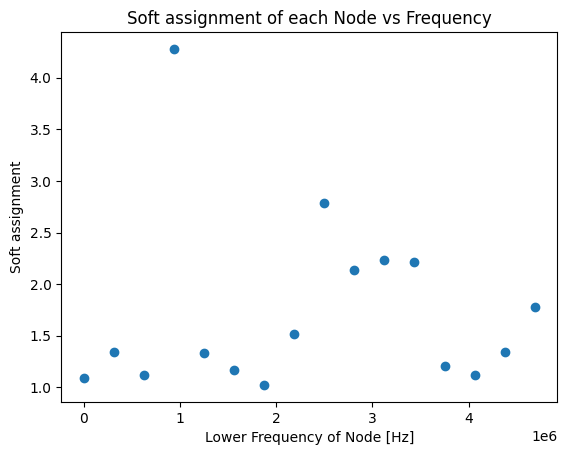

In [90]:
# plot weighted reassigned labels
plt.scatter([node.frequency_range[0] for node in new_wpt_df["node"]], new_soft_assignments)
plt.title("Soft assignment of each Node vs Frequency")
plt.xlabel("Lower Frequency of Node [Hz]")
plt.ylabel("Soft assignment")
plt.show()